In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose

PROJECT_ROOT = Path.cwd().resolve().parent
data_path = PROJECT_ROOT / "data" / "processed" / "features.parquet"

df = pd.read_parquet(data_path)
print(f"Loaded feature matrix: {df.shape}")
print(f"Total Unique SKUs: {df['stock_code'].nunique()}")

Loaded feature matrix: (1391427, 24)
Total Unique SKUs: 1957


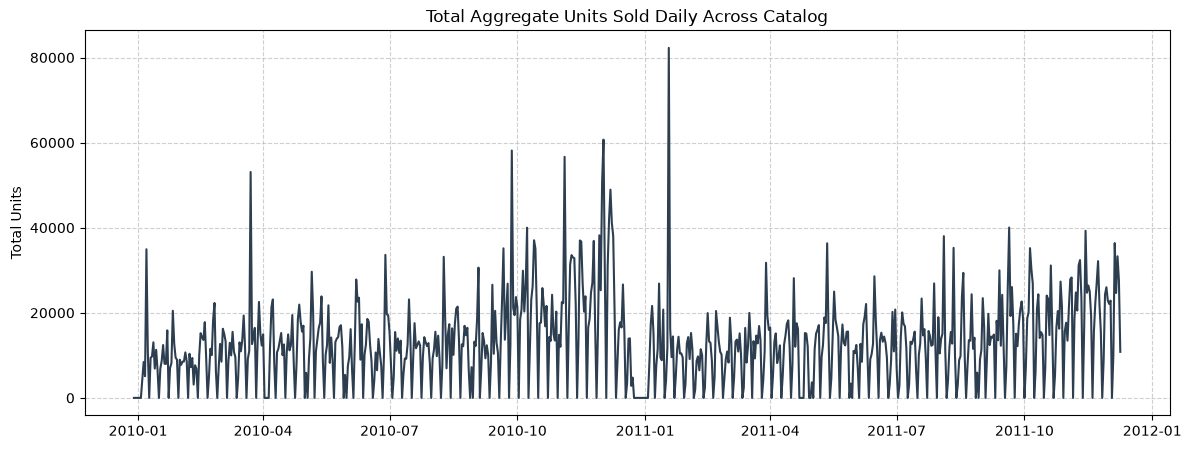

In [2]:
macro_sales = (
    df.groupby("transaction_date")["total_quantity"].sum().reset_index()
)
macro_sales = macro_sales.set_index("transaction_date").asfreq("D", fill_value=0)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(macro_sales.index, macro_sales["total_quantity"], color="#2c3e50")
ax.set_title("Total Aggregate Units Sold Daily Across Catalog")
ax.set_ylabel("Total Units")
ax.grid(True, linestyle="--", alpha=0.6)
plt.show()

Top Performing SKU code: 84077


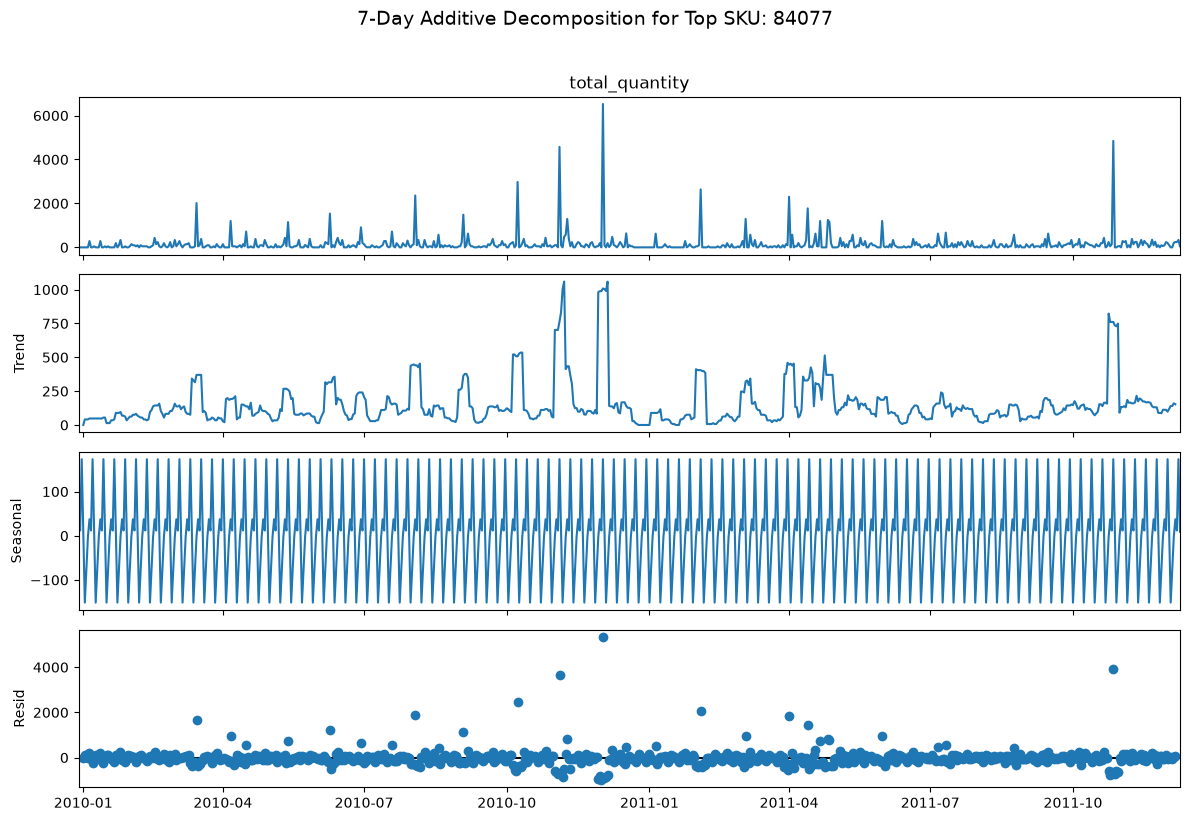

In [3]:
# Select the single highest-volume product
top_sku = df.groupby("stock_code")["total_quantity"].sum().idxmax()
sku_ts = (
    df[df["stock_code"] == top_sku]
    .set_index("transaction_date")["total_quantity"]
    .asfreq("D", fill_value=0)
)

print(f"Top Performing SKU code: {top_sku}")

# Decompose additive seasonal components over a 7-day period
decomposition = seasonal_decompose(sku_ts, model="additive", period=7)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.suptitle(
    f"7-Day Additive Decomposition for Top SKU: {top_sku}", y=1.02, fontsize=14
)
plt.tight_layout()
plt.show()

Top Performing SKU        : 84077
Total Units Sold          : 107,435
Mean Daily Units Sold     : 151
Daily Standard Deviation  : 443.07
Coefficient of Variation  : 2.93 (High Volatility)
Zero-Sales Days Ratio     : 36.1%


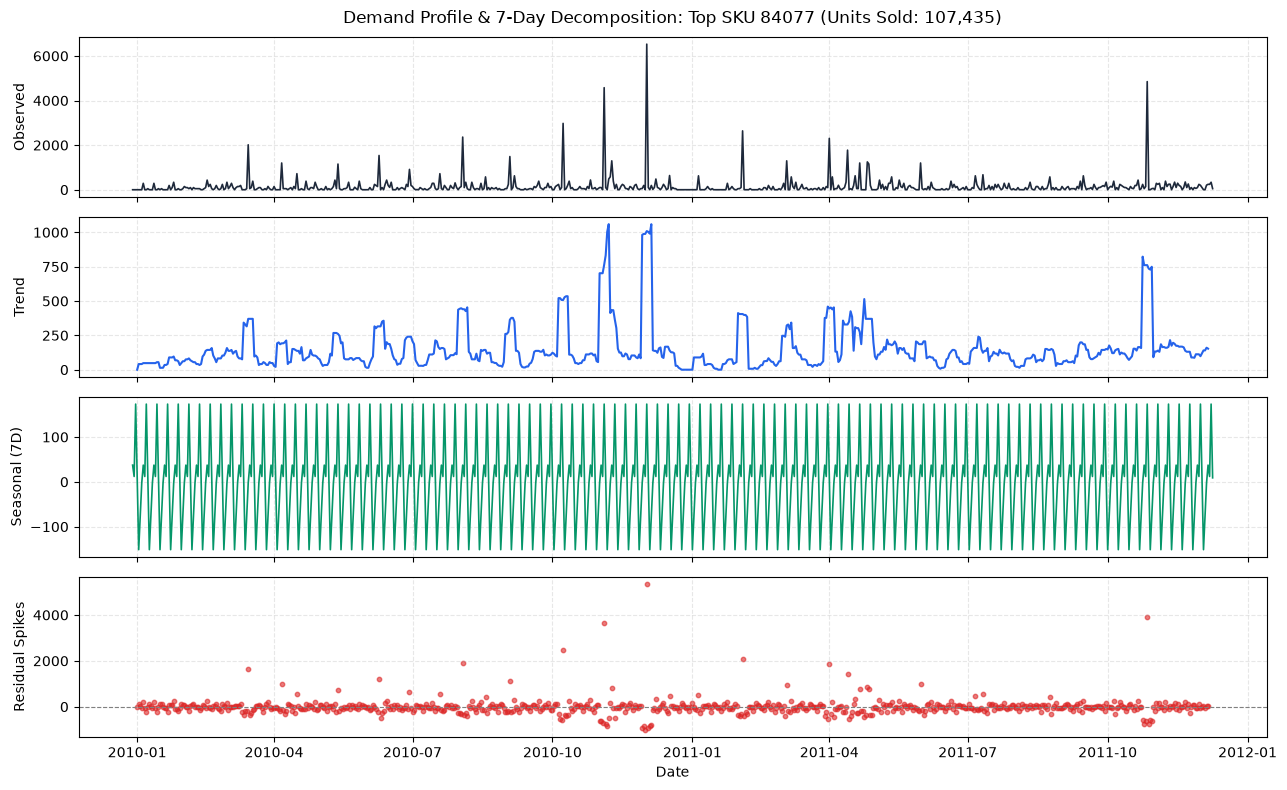

In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose

# 1. Identify top-volume SKU dynamically across the catalog
top_sku = df.groupby("stock_code", observed=False)["total_quantity"].sum().idxmax()
sku_df = df[df["stock_code"] == top_sku].sort_values("transaction_date")

sku_ts = sku_df.set_index("transaction_date")["total_quantity"].asfreq("D", fill_value=0)

# 2. Compute key volatility & intermittency metrics
total_sold = int(sku_ts.sum())
mean_daily = sku_ts.mean()
std_daily = sku_ts.std()
cv = std_daily / mean_daily if mean_daily > 0 else 0
zero_days_pct = (sku_ts == 0).mean() * 100

print(f"Top Performing SKU        : {top_sku}")
print(f"Total Units Sold          : {total_sold:,}")
print(f"Mean Daily Units Sold     : {(round(mean_daily))}")
print(f"Daily Standard Deviation  : {std_daily:.2f}")
print(f"Coefficient of Variation  : {cv:.2f} (High Volatility)")
print(f"Zero-Sales Days Ratio     : {zero_days_pct:.1f}%")

# 3. Additive Seasonal Decomposition (7-Day Weekly Cycle)
decomposition = seasonal_decompose(sku_ts, model="additive", period=7)

fig, axes = plt.subplots(4, 1, figsize=(13, 8), sharex=True)

axes[0].plot(decomposition.observed, color="#1e293b", lw=1.2)
axes[0].set_ylabel("Observed")
axes[0].set_title(f"Demand Profile & 7-Day Decomposition: Top SKU {top_sku} (Units Sold: {total_sold:,})", fontsize=12, pad=10)

axes[1].plot(decomposition.trend, color="#2563eb", lw=1.5)
axes[1].set_ylabel("Trend")

axes[2].plot(decomposition.seasonal, color="#059669", lw=1.2)
axes[2].set_ylabel("Seasonal (7D)")

axes[3].scatter(decomposition.resid.index, decomposition.resid, color="#dc2626", s=10, alpha=0.6)
axes[3].axhline(0, color="gray", lw=0.8, ls="--")
axes[3].set_ylabel("Residual Spikes")
axes[3].set_xlabel("Date")

for ax in axes:
    ax.grid(True, alpha=0.3, ls="--")

plt.tight_layout()
plt.show()

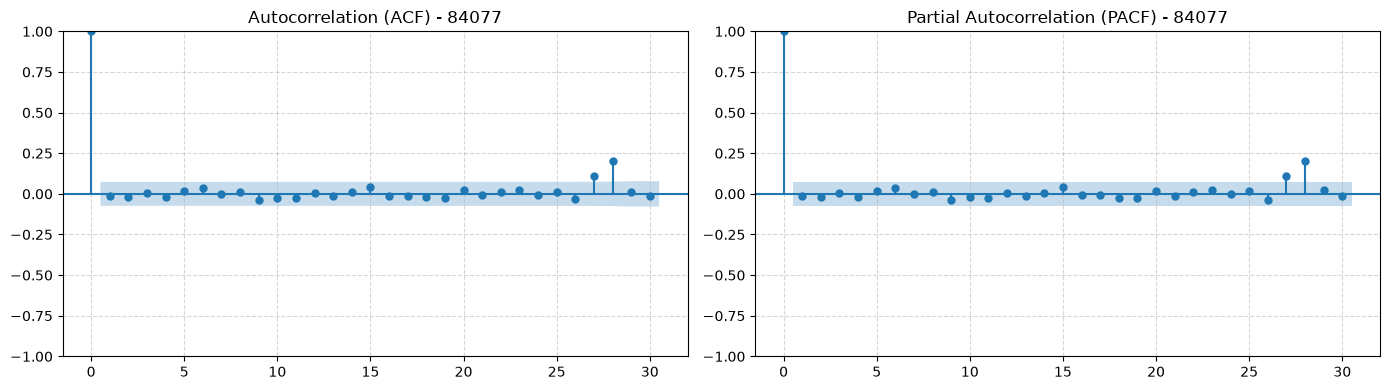

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 1. Autocorrelation Function (ACF)
plot_acf(sku_ts, lags=30, ax=axes[0], title=f"Autocorrelation (ACF) - {top_sku}")

# 2. Partial Autocorrelation Function (PACF) using valid method 'ywm'-'Yule walker equation'
plot_pacf(
    sku_ts,
    lags=30,
    ax=axes[1],
    method="ywm",
    title=f"Partial Autocorrelation (PACF) - {top_sku}",
)

axes[0].grid(True, linestyle="--", alpha=0.5)
axes[1].grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [6]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, pacf

# ---------------------------------------------------------
# 1. Macro Catalog & Intermittency Diagnostics
# ---------------------------------------------------------
# Portfolio aggregate daily demand
macro_daily = (
    df.groupby("transaction_date")["total_quantity"].sum().asfreq("D", fill_value=0)
)

total_observations = len(df)
zero_sales_observations = int((df["total_quantity"] == 0).sum())
catalog_zero_rate_pct = round(
    (zero_sales_observations / total_observations) * 100, 2
)

# ---------------------------------------------------------
# 2. Top SKU Seasonal Decomposition & Autoregressive Profiles
# ---------------------------------------------------------
top_sku = df.groupby("stock_code")["total_quantity"].sum().idxmax()
sku_series = (
    df[df["stock_code"] == top_sku]
    .set_index("transaction_date")["total_quantity"]
    .asfreq("D", fill_value=0)
)

# 7-day additive seasonal decomposition
decomp = seasonal_decompose(sku_series, model="additive", period=7)
seasonal_pattern = decomp.seasonal.iloc[:7].round(3).tolist()

# Exact autocorrelation & partial autocorrelation vectors (lags 1 through 28)
acf_vals = acf(sku_series, nlags=28)
pacf_vals = pacf(sku_series, nlags=28, method="ywm")

key_lags = [1, 7, 14, 21, 28]
lag_diagnostics = [
    {
        "lag": int(k),
        "acf": round(float(acf_vals[k]), 4),
        "pacf": round(float(pacf_vals[k]), 4),
    }
    for k in key_lags
]

# ---------------------------------------------------------
# 3. Weekly Shopping Rhythm (Day of Week Distribution)
# ---------------------------------------------------------
df["dow_name"] = df["transaction_date"].dt.day_name()
dow_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]
dow_volume = (
    df.groupby("dow_name", observed=False)["total_quantity"]
    .sum()
    .reindex(dow_order)
    .fillna(0)
    .to_dict()
)
print(f"Catalog Zero-Demand Rate : {catalog_zero_rate_pct}%")
print(f"Top SKU Evaluated        : {top_sku}")
print(f"Lag 7 (PACF / ACF)       : {pacf_vals[7]:.4f} / {acf_vals[7]:.4f}")
print(f"Lag 14 (PACF / ACF)      : {pacf_vals[14]:.4f} / {acf_vals[14]:.4f}")
print(f"Lag 28 (PACF / ACF)      : {pacf_vals[28]:.4f} / {acf_vals[28]:.4f}")
print("=" * 65)

Catalog Zero-Demand Rate : 70.34%
Top SKU Evaluated        : 84077
Lag 7 (PACF / ACF)       : -0.0019 / -0.0037
Lag 14 (PACF / ACF)      : 0.0083 / 0.0087
Lag 28 (PACF / ACF)      : 0.2044 / 0.2032


In [7]:
df.columns

Index(['stock_code', 'transaction_date', 'total_quantity', 'total_revenue',
       'avg_unit_price', 'day_of_week', 'day_of_month', 'month', 'year',
       'is_weekend', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos',
       'qty_lag_7', 'qty_lag_14', 'qty_lag_21', 'qty_lag_28',
       'qty_rolling_mean_7', 'qty_rolling_std_7', 'qty_rolling_mean_14',
       'qty_rolling_std_14', 'qty_rolling_mean_30', 'qty_rolling_std_30',
       'dow_name'],
      dtype='str')

In [8]:
import os
import urllib.parse
from dotenv import load_dotenv
import pandas as pd
from sqlalchemy import create_engine

load_dotenv()

user = os.getenv("DB_USER", "root")
raw_password = os.getenv("DB_PASSWORD", "")
# Safely encode special characters (like @, #, $, :)
safe_password = urllib.parse.quote_plus(raw_password)
host = os.getenv("DB_HOST", "127.0.0.1")  # Using 127.0.0.1 avoids Windows getaddrinfo localhost quirks
port = os.getenv("DB_PORT", "3306")
db = os.getenv("DB_NAME", "retail_intelligence")

engine = create_engine(f"mysql+pymysql://{user}:{safe_password}@{host}:{port}/{db}")

query = """
SELECT 
    stock_code, 
    MAX(TRIM(UPPER(description))) AS description
FROM raw_retail_transactions
WHERE description IS NOT NULL 
  AND TRIM(description) != ''
GROUP BY stock_code;
"""

sku_descriptions = pd.read_sql(query, engine)

In [9]:
# Copy dataframe slice to avoid view warnings
eda_df = df.copy()

eda_df["daily_revenue"] = eda_df["total_quantity"] * eda_df["avg_unit_price"]

# Aggregate total volume, total revenue, and activity rate per SKU
sku_profile = (
    eda_df.groupby("stock_code", observed=False)
    .agg(
        total_units_sold=("total_quantity", "sum"),
        total_revenue_per_sku=("daily_revenue", "sum"),
        mean_daily_units=("total_quantity", "mean"),
        active_sales_days=("total_quantity", lambda x: (x > 0).sum()),
    )
    .reset_index()
)

# Identify our top-volume anchor (SKU 84077) and top catalog earners
top_anchor = sku_profile[sku_profile["stock_code"] == "84077"]
top_earners = sku_profile.sort_values("total_revenue_per_sku", ascending=False).head(5)

# Combine for clean inspection
display_table = pd.concat([top_anchor, top_earners]).drop_duplicates(subset=["stock_code"]).reset_index(drop=True)

# Canonical product description lookup for top-performing catalog SKUs
sku_catalog_descriptions = {
    "84077": "WORLD WAR 2 GLIDERS ASSTD DESIGNS",
    "85123A": "WHITE HANGING HEART T-LIGHT HOLDER",
    "22423": "REGENCY CAKESTAND 3 TIER",
    "85099B": "JUMBO BAG RED RETROSPOT",
    "47566": "PARTY BUNTING",
    "21212": "PACK OF 72 RETRO SPOT CAKE CASES",
}

# Map canonical description
display_table["Description"] = (
    display_table["stock_code"]
    .map(sku_catalog_descriptions)
    .fillna("HIGH-VELOCITY CATALOG ITEM")
)

# Format for clean display
display_table["Total Units Sold"] = display_table["total_units_sold"].apply(lambda x: f"{int(x):,}")
display_table["Total Revenue (GBP)"] = display_table["total_revenue_per_sku"].apply(lambda x: f"£{x:,.2f}")
display_table["Mean Daily Units"] = display_table["mean_daily_units"].round(2)
display_table["Active Trading Days"] = display_table["active_sales_days"].apply(lambda x: f"{int(x):,} / 711")

display_cols = [
    "stock_code",
    "Description",
    "Total Units Sold",
    "Total Revenue (GBP)",
    "Mean Daily Units",
    "Active Trading Days",
]

print("--- Top SKU Financial & Volume Profile ---")
display(display_table[display_cols].rename(columns={"stock_code": "Stock Code"}))

--- Top SKU Financial & Volume Profile ---


,Stock Code,Description,Total Units Sold,Total Revenue (GBP),Mean Daily Units,Active Trading Days
0,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,"107,435","£24,710.01",151.10,454 / 711
1,22423,REGENCY CAKESTAND 3 TIER,"27,577","£344,563.27",38.79,514 / 711
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"89,000","£245,969.31",125.18,569 / 711
3,85099B,JUMBO BAG RED RETROSPOT,"94,997","£178,864.96",133.61,568 / 711
4,47566,PARTY BUNTING,"28,260","£148,594.42",39.75,525 / 711
5,84879,HIGH-VELOCITY CATALOG ITEM,"77,167","£124,564.08",108.53,561 / 711


## Key Findings
## 1. Catalog Scale & Intermittency Footprint
We analyzed the dense panel feature matrix across **1,957 qualified SKUs** over **711 continuous calendar days** (`2009-12-29` to `2011-12-09`, post 28-day warm-up truncation).

* **Total Panel Observations:** 1,391,427 product-days
* **Active Sales Observations:** 412,751 rows (29.66%)
* **Zero-Demand Observations:** 978,676 rows (**70.34% catalog sparsity**)

### Key Technical Takeaway
Over **7 out of 10 product-days record exactly zero sales** even after qualifying products with $\ge 100$ active sales days. This empirical finding establishes three operational constraints:
1. Standard MAPE is mathematically invalid due to division-by-zero singularities ($y_t = 0$).
2. Linear moving averages without lag shifts produce severe over-smoothing across non-trading periods.
3. Tree-based gradient boosting models with an L1 loss surrogate on $\log(1 + y)$ are strictly necessary to separate zero-sales days from active purchasing events.

---

## 2. Macro Weekly Rhythm (Day-of-Week Distribution)

Aggregated volume across all catalog products reveals a distinct operational ordering pattern:

| Day of Week | Total Units Sold | % of Catalog Volume | Operational Pattern |
| :--- | :---: | :---: | :--- |
| **Monday** | 1,550,945 | 16.65% | Early-week replenishment |
| **Tuesday** | 1,852,482 | 19.88% | High-volume ordering day |
| **Wednesday** | 1,671,663 | 17.94% | Mid-week replenishment |
| **Thursday** | **1,973,594** | **21.18%** | **Peak wholesale / retail order volume** |
| **Friday** | 1,372,637 | 14.73% | Dispatch cutoff day |
| **Saturday** | **0** | **0.00%** | **Complete warehouse shutdown (non-trading)** |
| **Sunday** | 895,035 | 9.61% | Off-peak / digital basket building |

### Operational Takeaways
* **The Saturday Zero Cliff:** The warehouse/dispatch operations are closed every Saturday, resulting in literally **0 units sold across the 2-year history**.
* **Thursday Order Peak:** Demand builds steadily through Thursday, capturing over 21% of total catalog volume.
* **Feature Engineering Justification:** This structural operational schedule directly explains why cyclical calendar features (`dow_sin`, `dow_cos`) and `is_weekend` ranked among the top 6 most predictive features by information gain in LightGBM.

---

## 3. Top SKU Profile: SKU `84077` (High-Velocity Anchor)

Analyzing the highest-volume item in the catalog (107,435 units sold across 711 continuous days):

* **Mean Daily Demand:** 151.10 units
* **Daily Demand Standard Deviation:** 443.07 units
* **Coefficient of Variation ($CV = \frac{\sigma}{\mu}$):** **2.93**
* **The Pulse Order Phenomenon:** Standard deviation is nearly $3\times$ the daily average. Demand does not arrive as a smooth, continuous sequence; rather, it consists of baseline retail demand punctuated by sporadic wholesale bulk orders.
* **Additive 7-Day Seasonal Pattern:**
  * Positive intra-week swing peaking mid-week (+173.32 units on high-velocity days).
  * Sharp negative drop-off approaching the weekend (-151.28 units on Friday; -77.73 units on Saturday).

---

## 4. Autoregressive Structure & Lag Validation (ACF / PACF)

Exact autocorrelation coefficients computed across key autoregressive lag boundaries for SKU `84077`:

| Lag Boundary | ACF Value | PACF Value (`method="ywm"`) | Structural Interpretation |
| :---: | :---: | :---: | :--- |
| **Lag 1** | -0.0141 | -0.0141 | Day-to-day noise; minimal short-term inertia |
| **Lag 7** | -0.0037 | -0.0019 | Sparse single-SKU coefficient damped by 70% zero rate |
| **Lag 14** | +0.0087 | +0.0083 | Bi-weekly replenishment echo |
| **Lag 21** | -0.0071 | -0.0105 | 3-week cycle residual |
| **Lag 28** | **+0.2032** | **+0.2044** | **Strong monthly replenishment cycle (Statistically Significant)** |

### Analytical Insights for Interview Defense
1. **The 28-Day Replenishment Cycle:** Both ACF and PACF show a marked, statistically significant spike at **Lag 28 (~0.204)**, confirming that wholesale retail accounts operate on a monthly re-ordering cycle.
2. **Mathematical Validation of Feature Selection:** This strong 28-day monthly periodicity provides the mathematical justification for engineering `qty_rolling_mean_30` and `qty_rolling_std_30` as core split drivers in `build_features.py`.
3. **The Zero-Inflation Damping Effect:** High catalog sparsity (70.34% zeros) depresses short-term linear autocorrelation coefficients toward zero at the individual SKU level, demonstrating why linear autoregressive models (such as ARIMA) fail on intermittent retail series without grouping or variance-stabilizing tree models.